In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

sys.path.insert(0, str(PROJECT_ROOT))

from src.metrics import (
    calculate_no_show_rate,
    calculate_referral_completion_rate
)

DATA_DIR = PROJECT_ROOT / "data" / "processed"

patients = pd.read_csv(DATA_DIR / "patients.csv")
appointments = pd.read_csv(DATA_DIR / "appointments.csv")
referrals = pd.read_csv(DATA_DIR / "referrals.csv")

In [2]:
no_show_rate = calculate_no_show_rate(appointments)

referral_completion_rate = (
    calculate_referral_completion_rate(referrals)
)

print(f"No-show Rate: {no_show_rate:.2%}")
print(
    "Referral Completion Rate: "
    f"{referral_completion_rate:.2%}"
)

No-show Rate: 8.55%
Referral Completion Rate: 54.50%


In [3]:
analysis_df = appointments.merge(
    patients[["study_patient_id", "pcp_id"]],
    on="study_patient_id",
    how="left",
    validate="many_to_one"
)

eligible = analysis_df[
    analysis_df["appointment_status"].isin(
        ["Completed", "No-show"]
    )
].copy()

eligible["is_no_show"] = (
    eligible["appointment_status"] == "No-show"
)

pcp_summary = (
    eligible.groupby("pcp_id")
    .agg(
        total_appointments=("is_no_show", "size"),
        no_show_rate=("is_no_show", "mean")
    )
    .reset_index()
)

display(pcp_summary)

,pcp_id,total_appointments,no_show_rate
0,PCP_A,2396,0.084725
1,PCP_B,2432,0.089638
2,PCP_C,2311,0.080485
3,PCP_D,2441,0.089308
4,PCP_E,2230,0.082960


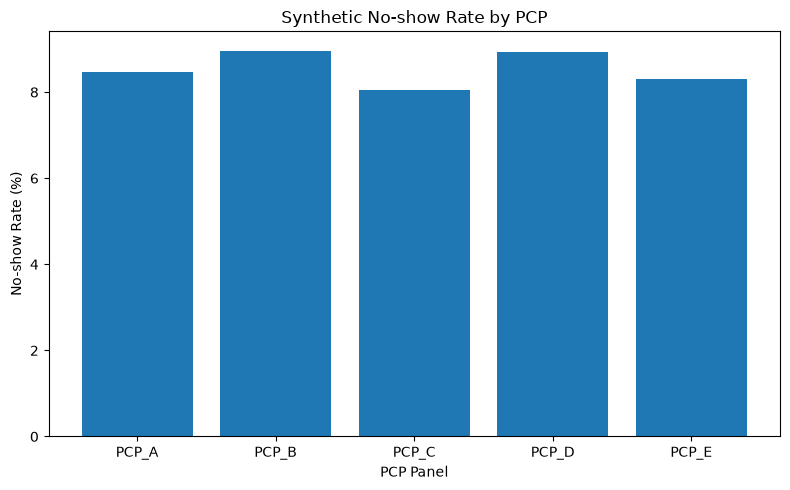

In [4]:
plt.figure(figsize=(8, 5))

plt.bar(
    pcp_summary["pcp_id"],
    pcp_summary["no_show_rate"] * 100
)

plt.xlabel("PCP Panel")
plt.ylabel("No-show Rate (%)")
plt.title("Synthetic No-show Rate by PCP")

plt.tight_layout()
plt.show()